In [2]:
!pip install ucimlrepo -q

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from ucimlrepo import fetch_ucirepo

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("Libraries imported successfully!")



Libraries imported successfully!


In [3]:
phishing = fetch_ucirepo(id=327)

X = phishing.data.features
y = phishing.data.targets.iloc[:, 0]

print("Dataset loaded successfully!")
print("Features shape:", X.shape)
print("Target shape:", y.shape)

display(X.head())


Dataset loaded successfully!
Features shape: (11055, 30)
Target shape: (11055,)


,having_ip_address,url_length,shortining_service,having_at_symbol,double_slash_redirecting,prefix_suffix,having_sub_domain,sslfinal_state,domain_registration_length,favicon,...,rightclick,popupwindow,iframe,age_of_domain,dnsrecord,web_traffic,page_rank,google_index,links_pointing_to_page,statistical_report
0,-1,1,1,1,-1,-1,-1,-1,-1,1,...,1,1,1,-1,-1,-1,-1,1,1,-1
1,1,1,1,1,1,-1,0,1,-1,1,...,1,1,1,-1,-1,0,-1,1,1,1
2,1,0,1,1,1,-1,-1,-1,-1,1,...,1,1,1,1,-1,1,-1,1,0,-1
3,1,0,1,1,1,-1,-1,-1,1,1,...,1,1,1,-1,-1,1,-1,1,-1,1
4,1,0,-1,1,1,-1,1,1,-1,1,...,1,-1,1,-1,-1,0,-1,1,1,1


In [4]:
print("Dataset information:")
X.info()

print("\nMissing values:")
print(X.isnull().sum().sum())

print("\nStatistical summary:")
display(X.describe())

print("\nClass distribution:")
print(y.value_counts())


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11055 entries, 0 to 11054
Data columns (total 30 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   having_ip_address           11055 non-null  int64
 1   url_length                  11055 non-null  int64
 2   shortining_service          11055 non-null  int64
 3   having_at_symbol            11055 non-null  int64
 4   double_slash_redirecting    11055 non-null  int64
 5   prefix_suffix               11055 non-null  int64
 6   having_sub_domain           11055 non-null  int64
 7   sslfinal_state              11055 non-null  int64
 8   domain_registration_length  11055 non-null  int64
 9   favicon                     11055 non-null  int64
 10  port                        11055 non-null  int64
 11  https_token                 11055 non-null  int64
 12  request_url                 11055 non-null  int64
 13  url_of_anchor               11055 non-nu

,having_ip_address,url_length,shortining_service,having_at_symbol,double_slash_redirecting,prefix_suffix,having_sub_domain,sslfinal_state,domain_registration_length,favicon,...,rightclick,popupwindow,iframe,age_of_domain,dnsrecord,web_traffic,page_rank,google_index,links_pointing_to_page,statistical_report
count,11055.000000,11055.000000,11055.000000,11055.000000,11055.000000,11055.000000,11055.000000,11055.000000,11055.000000,11055.000000,...,11055.000000,11055.000000,11055.000000,11055.000000,11055.000000,11055.000000,11055.000000,11055.000000,11055.000000,11055.000000
mean,0.313795,-0.633198,0.738761,0.700588,0.741474,-0.734962,0.063953,0.250927,-0.336771,0.628584,...,0.913885,0.613388,0.816915,0.061239,0.377114,0.287291,-0.483673,0.721574,0.344007,0.719584
std,0.949534,0.766095,0.673998,0.713598,0.671011,0.678139,0.817518,0.911892,0.941629,0.777777,...,0.405991,0.789818,0.576784,0.998168,0.926209,0.827733,0.875289,0.692369,0.569944,0.694437
min,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,...,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000
25%,-1.000000,-1.000000,1.000000,1.000000,1.000000,-1.000000,-1.000000,-1.000000,-1.000000,1.000000,...,1.000000,1.000000,1.000000,-1.000000,-1.000000,0.000000,-1.000000,1.000000,0.000000,1.000000
50%,1.000000,-1.000000,1.000000,1.000000,1.000000,-1.000000,0.000000,1.000000,-1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,-1.000000,1.000000,0.000000,1.000000
75%,1.000000,-1.000000,1.000000,1.000000,1.000000,-1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000



Class distribution:
result
 1    6157
-1    4898
Name: count, dtype: int64


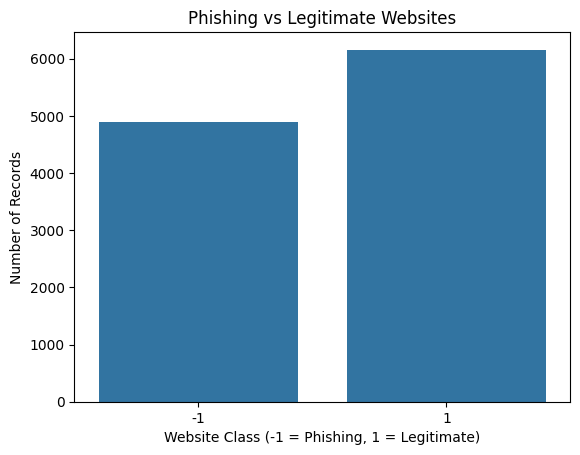

In [5]:
sns.countplot(x=y)

plt.title("Phishing vs Legitimate Websites")
plt.xlabel("Website Class (-1 = Phishing, 1 = Legitimate)")
plt.ylabel("Number of Records")

plt.show()



In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))


Training records: 8844
Testing records: 2211


In [7]:
dt_model = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

dt_model.fit(X_train, y_train)

print("Decision Tree trained successfully!")



Decision Tree trained successfully!


In [8]:
lr_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000))
])

lr_model.fit(X_train, y_train)

print("Logistic Regression trained successfully!")


Logistic Regression trained successfully!


In [9]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    random_state=42
)

rf_model.fit(X_train, y_train)

print("Random Forest trained successfully!")


Random Forest trained successfully!


In [10]:
models = {
    "Decision Tree": dt_model,
    "Logistic Regression": lr_model,
    "Random Forest": rf_model
}

results = []

for name, model in models.items():

    predictions = model.predict(X_test)

    accuracy = accuracy_score(y_test, predictions)

    precision = precision_score(
        y_test, predictions, pos_label=-1
    )

    recall = recall_score(
        y_test, predictions, pos_label=-1
    )

    f1 = f1_score(
        y_test, predictions, pos_label=-1
    )

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

comparison = pd.DataFrame(results)

display(comparison.round(4))


,Model,Accuracy,Precision,Recall,F1 Score
0,Decision Tree,0.9267,0.9485,0.8827,0.9144
1,Logistic Regression,0.9285,0.9354,0.9010,0.9179
2,Random Forest,0.9557,0.9691,0.9296,0.9490


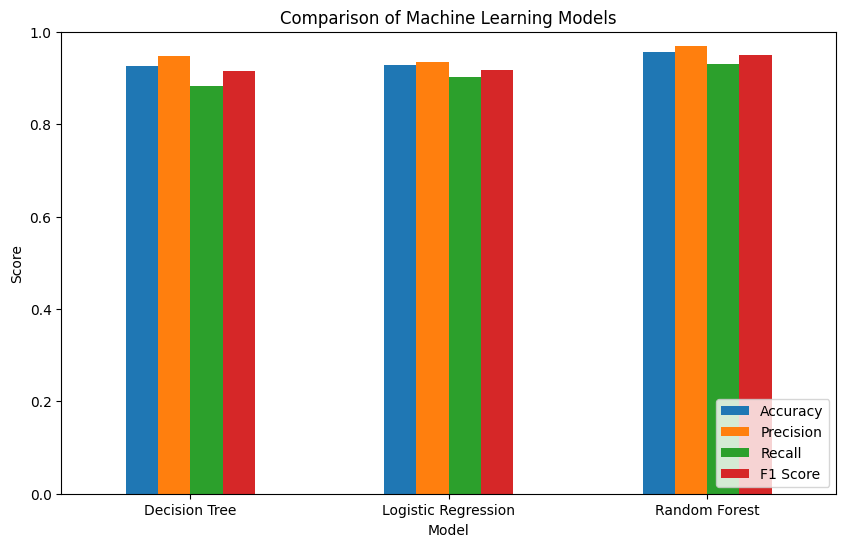

In [11]:
comparison.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1 Score"]
].plot(kind="bar", figsize=(10, 6))

plt.title("Comparison of Machine Learning Models")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")

plt.show()


In [12]:
best_model_name = comparison.loc[
    comparison["F1 Score"].idxmax(), "Model"
]

best_model = models[best_model_name]

print("Best model:", best_model_name)


Best model: Random Forest


In [13]:
best_predictions = best_model.predict(X_test)

print("Selected Model:", best_model_name)

print(
    classification_report(
        y_test,
        best_predictions,
        target_names=["Phishing", "Legitimate"],
        labels=[-1, 1]
    )
)


Selected Model: Random Forest
              precision    recall  f1-score   support

    Phishing       0.97      0.93      0.95       980
  Legitimate       0.95      0.98      0.96      1231

    accuracy                           0.96      2211
   macro avg       0.96      0.95      0.95      2211
weighted avg       0.96      0.96      0.96      2211



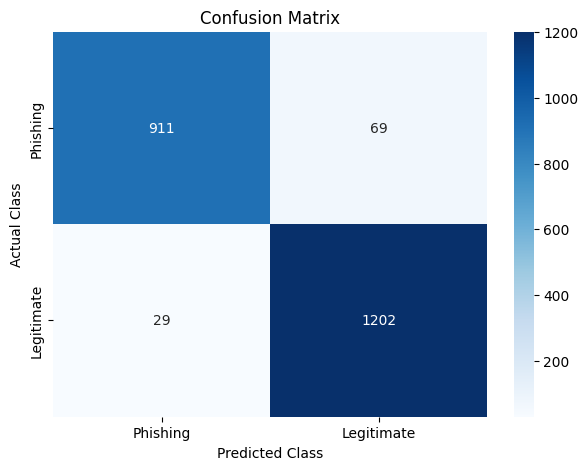

In [14]:
cm = confusion_matrix(
    y_test,
    best_predictions,
    labels=[-1, 1]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Phishing", "Legitimate"],
    yticklabels=["Phishing", "Legitimate"]
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Confusion Matrix")

plt.show()


Top 10 important features:


,0
sslfinal_state,0.767022
url_of_anchor,0.131594
web_traffic,0.029902
links_in_tags,0.029431
prefix_suffix,0.014918
domain_registration_length,0.011563
having_sub_domain,0.010319
links_pointing_to_page,0.003678
iframe,0.000762
url_length,0.000521


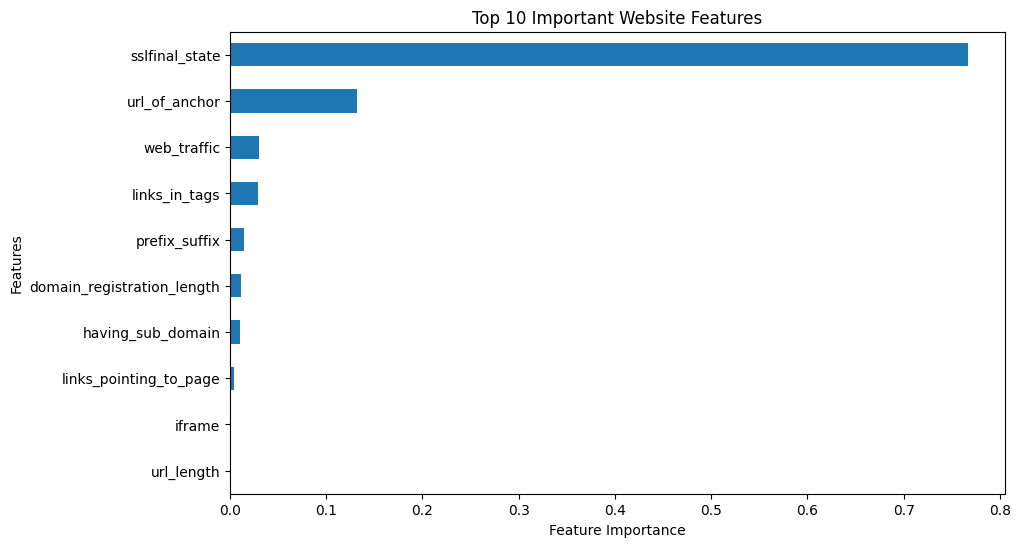

In [15]:
importance = pd.Series(
    dt_model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print("Top 10 important features:")
display(importance.head(10))

plt.figure(figsize=(10, 6))

importance.head(10).sort_values().plot(kind="barh")

plt.title("Top 10 Important Website Features")
plt.xlabel("Feature Importance")
plt.ylabel("Features")

plt.show()


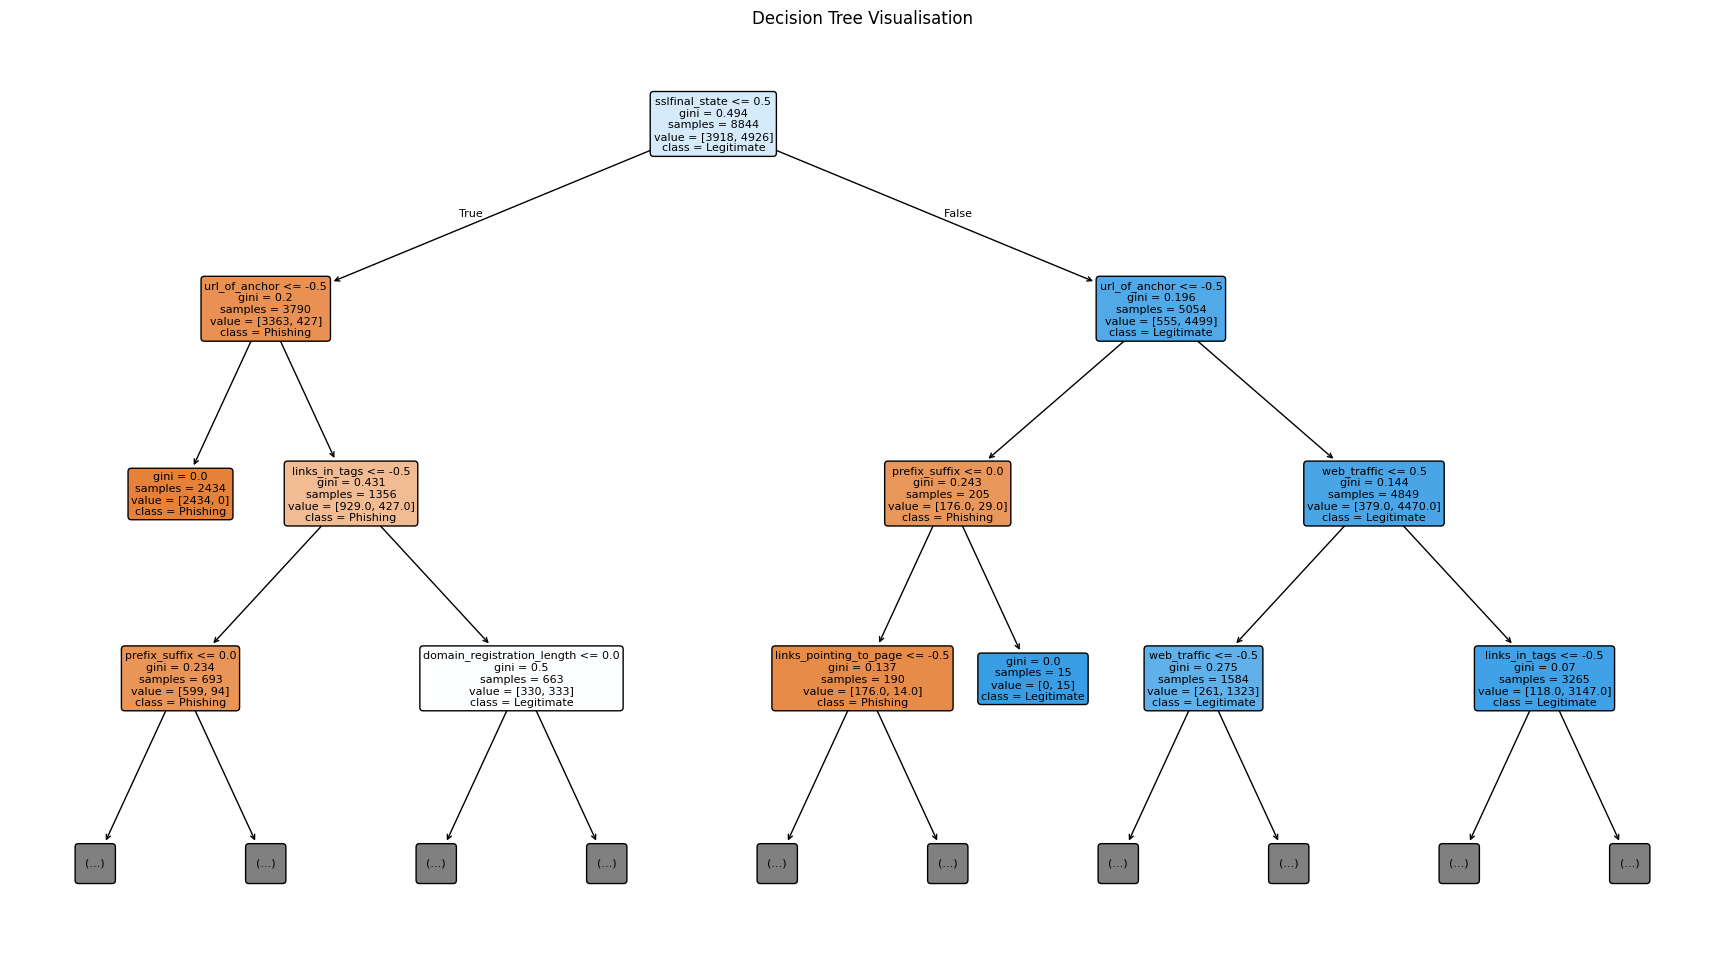

In [16]:
plt.figure(figsize=(22, 12))

plot_tree(
    dt_model,
    feature_names=list(X.columns),
    class_names=["Phishing", "Legitimate"],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8
)

plt.title("Decision Tree Visualisation")
plt.show()


In [17]:
sample_data = X_test.iloc[:10]

sample_predictions = best_model.predict(sample_data)

sample_results = pd.DataFrame({
    "Actual": y_test.iloc[:10].values,
    "Predicted": sample_predictions
})

sample_results["Actual Class"] = (
    sample_results["Actual"].map({
        -1: "Phishing",
        1: "Legitimate"
    })
)

sample_results["Predicted Class"] = (
    sample_results["Predicted"].map({
        -1: "Phishing",
        1: "Legitimate"
    })
)

display(sample_results)


,Actual,Predicted,Actual Class,Predicted Class
0,-1,-1,Phishing,Phishing
1,-1,-1,Phishing,Phishing
2,1,1,Legitimate,Legitimate
3,-1,-1,Phishing,Phishing
4,-1,-1,Phishing,Phishing
5,1,1,Legitimate,Legitimate
6,1,1,Legitimate,Legitimate
7,1,1,Legitimate,Legitimate
8,1,1,Legitimate,Legitimate
9,-1,-1,Phishing,Phishing


In [18]:
joblib.dump(dt_model, "decision_tree_model.pkl")

joblib.dump(lr_model, "logistic_regression_model.pkl")

joblib.dump(rf_model, "random_forest_model.pkl")

joblib.dump(best_model, "best_phishing_model.pkl")

print("All models saved successfully!")


All models saved successfully!
